# the workflow

User specify a grid id and date

1. using easyidp to crop point clouds - offsets
2. read the broccoli head position - offsets
3. read the 2D broccoli traits + automl model -> predicted 2D traits
4. find the closest tempalte from the 3D mesh database -> the transfomation + mesh path
5. preview by open3d
5. save previous info to temp file (json / npy)
6. blender python API, read json file, and display

Please use the AMD3090 PC, and ctrl+shift+P connect to WSL server, and using the (lab) enviroment to run this notebook

(Linux auto-sklearn required)

In [21]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(suppress=True)
import pandas as pd
import seaborn as sns
import open3d as o3d
import autosklearn as askl

from copy import copy
from shapely.geometry.polygon import Polygon
from scipy.spatial.transform import Rotation 

import easyidp as idp

In [2]:
date = '220405'
grid_id = '29'

# 2. read the broccoli head position

In [3]:
from broccoli_file_path import *

In [4]:
idp.shp.show_shp_fields(grid_shp)

  [-1]   [0] id    [1] left      [2] top     [3] right    [4] bottom
------  --------  -----------  -----------  -----------  ------------
     0     1      368059.3728  3956070.552  368061.8728  3956068.052
     1     2      368059.3728  3956068.052  368061.8728  3956065.552
     2     3      368059.3728  3956065.552  368061.8728  3956063.052
   ...    ...         ...          ...          ...          ...
   501    594     368116.8728  3956025.552  368119.3728  3956023.052
   502    595     368116.8728  3956023.052  368119.3728  3956020.552
   503    596     368116.8728  3956020.552  368119.3728  3956018.052


In [5]:
grid = idp.ROI(grid_shp, name_field='id')
grid

[shp][proj] Use projection [WGS 84 / UTM zone 54N] for loaded shapefile [split_grid.shp]


Read shapefile [split_grid.shp]: 100%|██████████| 504/504 [00:13<00:00, 38.75it/s]


<easyidp.ROI> with 504 items
[0]	1
array([[ 368058.59787001, 3956058.88557004],
       [ 368061.04143287, 3956059.41377509],
       [ 368061.56963791, 3956056.97021223],
       [ 368059.12607505, 3956056.44200719],
       [ 368058.59787001, 3956058.88557004]])
[1]	2
array([[ 368059.12607505, 3956056.44200719],
       [ 368061.56963791, 3956056.97021223],
       [ 368062.09784295, 3956054.52664938],
       [ 368059.6542801 , 3956053.99844433],
       [ 368059.12607505, 3956056.44200719]])
...
[502]	595
array([[ 368124.83571154, 3956024.6065918 ],
       [ 368127.27927439, 3956025.13479684],
       [ 368127.80747944, 3956022.69123398],
       [ 368125.36391658, 3956022.16302894],
       [ 368124.83571154, 3956024.6065918 ]])
[503]	596
array([[ 368125.36391658, 3956022.16302894],
       [ 368127.80747944, 3956022.69123398],
       [ 368128.33568448, 3956020.24767113],
       [ 368125.89212163, 3956019.71946608],
       [ 368125.36391658, 3956022.16302894]])

In [6]:
pcd = idp.PointCloud(process_date[date]['pcd'])
pcd

                    x            y        z  r    g    b        nx      ny      nz
        0  368057.379  3956051.919   96.685  177  177  161  nodata  nodata  nodata
        1  368057.405  3956051.796   96.689  144  141  122  nodata  nodata  nodata
        2  368057.403  3956051.803   96.687  141  138  118  nodata  nodata  nodata
      ...     ...          ...      ...      ...  ...  ...     ...     ...     ...
123187743  368133.04   3956019.956   96.643  88   107  78   nodata  nodata  nodata
123187744  368132.9    3956019.851   96.663  114  149  123  nodata  nodata  nodata
123187745  368132.895  3956019.882   96.66   119  115  99   nodata  nodata  nodata

In [7]:
grid_pcd = pcd.crop_point_cloud(grid[grid_id])
grid_pcd._update_btf_print()
grid_pcd

                 x            y        z  r    g    b        nx      ny      nz
     0  368062.752  3956051.579   96.623  92   71   63   nodata  nodata  nodata
     1  368062.791  3956051.362   96.626  66   49   40   nodata  nodata  nodata
     2  368062.782  3956051.384   96.633  60   42   36   nodata  nodata  nodata
   ...     ...          ...      ...      ...  ...  ...     ...     ...     ...
222244  368065.494  3956050.161   96.88   113  138  127  nodata  nodata  nodata
222245  368065.416  3956050.237   96.943  159  180  176  nodata  nodata  nodata
222246  368065.37   3956050.136   96.883  71   99   93   nodata  nodata  nodata

In [8]:
grid_pcd.offset

array([ 368000., 3956000.,       0.])

In [9]:
grid_pcd._points

array([[62.7519, 51.5788, 96.6231],
       [62.7906, 51.3622, 96.6255],
       [62.7817, 51.3843, 96.6327],
       ...,
       [65.4945, 50.1606, 96.8798],
       [65.416 , 50.2368, 96.9428],
       [65.3702, 50.1364, 96.8831]])

calcualte the grid center

In [10]:
grid_ctr = (grid_pcd._points.max(axis=0) + grid_pcd._points.min(axis=0)) / 2
grid_ctr

array([64.11165, 51.12495, 96.7841 ])

In [11]:
grid_pcd.update_offset_value(grid_pcd.offset + grid_ctr)

In [12]:
grid_pcd._points

array([[-1.35975,  0.45385, -0.161  ],
       [-1.32105,  0.23725, -0.1586 ],
       [-1.32995,  0.25935, -0.1514 ],
       ...,
       [ 1.38285, -0.96435,  0.0957 ],
       [ 1.30435, -0.88815,  0.1587 ],
       [ 1.25855, -0.98855,  0.099  ]])

In [13]:
grid_pcd.offset

array([ 368064.11165, 3956051.12495,      96.7841 ])

# 3. read broccoli head positions

In [14]:
broccoli_2d_traits = pd.read_excel('./out/props_all_2022.xlsx')
broccoli_2d_traits.head()

,date,label,area,convex_area,eccentricity,equivalent_diameter,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
0,20220321_0,275,2195,2301,0.662845,52.865497,61.468791,46.025174,55.977211,48.827068,183.923882,0.815395,368061.303157,3.956057e+06,28.569196,"[[368061.2815551026, 3956057.0713307424], [368..."
1,20220321_0,274,2512,2655,0.589631,56.554202,63.261803,51.094847,61.040001,52.439999,203.237590,0.764225,368061.039693,3.956057e+06,29.892332,"[[368061.0091929504, 3956057.388480319], [3680..."
2,20220321_0,141,2640,2708,0.486063,57.977171,62.220264,54.375771,62.156914,52.682552,197.438600,0.851039,368060.651307,3.956057e+06,30.560149,"[[368060.6217213799, 3956056.8345038854], [368..."
3,20220321_0,3,1625,1783,0.570272,45.486418,50.724595,41.668026,52.485325,38.600506,169.852814,0.707812,368059.888442,3.956057e+06,25.026932,"[[368059.87077905197, 3956057.177263872], [368..."
4,20220321_0,276,2979,3121,0.390530,61.587179,64.470901,59.351282,62.162289,61.676651,214.066017,0.816930,368061.327088,3.956057e+06,32.678574,"[[368061.2979172566, 3956056.8109018467], [368..."


find out the results in the given grid

In [15]:
grid_xymin = grid[grid_id].min(axis=0)
grid_xymax = grid[grid_id].max(axis=0)

using the min-max bbox to first filter points

In [16]:
in_grid_idx = (broccoli_2d_traits.date == f"20{date}_0") & \
(broccoli_2d_traits.circular_x > grid_xymin[0]) & (broccoli_2d_traits.circular_x < grid_xymax[0]) & \
(broccoli_2d_traits.circular_y > grid_xymin[1]) & (broccoli_2d_traits.circular_y < grid_xymax[1])

In [17]:
broccoli_2d_in_grid = broccoli_2d_traits[in_grid_idx]
print(broccoli_2d_in_grid.shape)
broccoli_2d_in_grid.head()

(34, 16)


,date,label,area,convex_area,eccentricity,equivalent_diameter,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
35413,20220405_0,293,11960,12401,0.361594,123.401560,128.197428,119.523051,124.452240,120.723137,438.646753,0.781108,368062.681637,3.956051e+06,63.886911,"[[368062.6274081238, 3956050.690029946], [3680..."
35415,20220405_0,296,9677,9853,0.369113,111.000626,115.462202,107.308782,112.331573,105.643127,373.747258,0.870552,368062.896898,3.956050e+06,57.218337,"[[368062.84242338774, 3956049.6953599676], [36..."
35417,20220405_0,295,12988,13479,0.411276,128.595627,135.760721,123.747373,134.143112,124.775574,452.386868,0.797503,368062.628659,3.956050e+06,67.561855,"[[368062.56827418495, 3956049.9056673567], [36..."
35803,20220405_0,561,12665,13020,0.400500,126.986530,133.045709,121.909328,126.450829,122.090462,441.688384,0.815799,368063.484944,3.956052e+06,65.832506,"[[368063.42747584445, 3956052.3753927085], [36..."
35807,20220405_0,425,1956,2334,0.923098,49.904474,82.678111,31.795106,79.554359,34.122959,239.178716,0.429669,368062.904993,3.956053e+06,33.601379,"[[368062.8806613569, 3956052.6232075603], [368..."


In [18]:
grid_polygon = Polygon(grid[grid_id])
in_grid_poly_inx = []
for i, val in broccoli_2d_in_grid.iterrows():
    bro_head_polygon = Polygon(eval(val.polygon))

    in_grid_poly_inx.append( grid_polygon.contains(bro_head_polygon) )

broccoli_2d_in_grid_poly = broccoli_2d_in_grid[in_grid_poly_inx].reset_index()
broccoli_2d_in_grid_poly.shape
broccoli_2d_in_grid_poly


,index,date,label,area,convex_area,eccentricity,equivalent_diameter,major_axis_length,minor_axis_length,min_area_rect_max,min_area_rect_min,perimeter,circularity,circular_x,circular_y,circular_r,polygon
0,35810,20220405_0,833,20672,21471,0.454876,162.235655,172.479149,153.602136,164.053268,163.905670,581.570635,0.768046,368065.219168,3.956051e+06,84.729245,"[[368065.1326798832, 3956051.29927134], [36806..."
1,35811,20220405_0,832,14473,14882,0.271418,135.748282,138.963896,133.747404,140.579193,134.985550,468.558441,0.828402,368065.121916,3.956052e+06,70.495404,"[[368065.06443522876, 3956051.6657725866], [36..."
2,35812,20220405_0,835,13738,14208,0.289326,132.256436,135.790101,129.982458,132.826843,128.536301,464.859956,0.798894,368065.364716,3.956051e+06,68.357779,"[[368065.29429905786, 3956050.646875522], [368..."
3,35813,20220405_0,836,18965,19915,0.534334,155.393011,171.202751,144.713097,165.300674,154.484009,571.600072,0.729421,368065.436652,3.956050e+06,81.821574,"[[368065.352541244, 3956050.244492501], [36806..."
4,35814,20220405_0,834,14411,14889,0.495827,135.457208,145.901919,126.704309,144.996597,125.647179,477.014285,0.795868,368065.186534,3.956051e+06,70.158017,"[[368065.11606531375, 3956050.9468036722], [36..."
5,35815,20220405_0,696,8757,9062,0.236272,105.592418,107.569689,104.524054,105.528870,105.271355,365.504617,0.823720,368064.553668,3.956052e+06,54.823512,"[[368064.51072343026, 3956052.0072663263], [36..."
6,35816,20220405_0,695,19403,19924,0.345554,157.177183,163.156787,153.106137,153.714844,150.484024,551.872150,0.800575,368064.383479,3.956052e+06,81.841934,"[[368064.30633461376, 3956052.3324036747], [36..."
7,35817,20220405_0,699,16864,17448,0.324280,146.532971,151.554570,143.364756,150.468124,146.441711,514.801082,0.799635,368064.775974,3.956051e+06,76.403480,"[[368064.70855837927, 3956050.9027786255], [36..."
8,35818,20220405_0,697,18184,18823,0.373334,152.159745,159.207406,147.696256,161.533127,148.361313,535.972655,0.795452,368064.555695,3.956052e+06,80.709552,"[[368064.4803976536, 3956051.6192022427], [368..."
9,35819,20220405_0,698,14832,15698,0.435662,137.421574,145.928467,131.351734,145.936432,130.530136,499.209199,0.747902,368064.622548,3.956051e+06,72.345246,"[[368064.56064085115, 3956051.2533214027], [36..."


select the necessary part for auto-sklern

In [19]:
# supress SettingWithCopyWarning
pd.set_option('mode.chained_assignment',None)

X = broccoli_2d_in_grid_poly[[
    'major_axis_length', 'minor_axis_length', 
    'min_area_rect_min', 'min_area_rect_max',
    'area', 'convex_area',
]]
X.major_axis_length /= 1000
X.minor_axis_length /= 1000
X.min_area_rect_max /= 1000
X.min_area_rect_min /= 1000
X.area /= 100
X.convex_area /= 100

X.head()

,major_axis_length,minor_axis_length,min_area_rect_min,min_area_rect_max,area,convex_area
0,0.172479,0.153602,0.163906,0.164053,206.72,214.71
1,0.138964,0.133747,0.134986,0.140579,144.73,148.82
2,0.135790,0.129982,0.128536,0.132827,137.38,142.08
3,0.171203,0.144713,0.154484,0.165301,189.65,199.15
4,0.145902,0.126704,0.125647,0.144997,144.11,148.89


load the auto-sklearn model"

In [23]:
random_state = 1
train_size = 0.8

In [24]:
with open(f'out/autoskl_{askl.__version__}_model_{random_state}.pkl', 'rb') as handle:
    automl = pickle.load(handle)

In [25]:
predictions = automl.predict(X.values)

predictions = pd.DataFrame(columns=X.columns, data=predictions)
predictions.head()

,major_axis_length,minor_axis_length,min_area_rect_min,min_area_rect_max,area,convex_area
0,0.174978,0.165332,0.164297,0.169320,221.830478,224.476998
1,0.151655,0.140850,0.144480,0.141356,162.618013,166.475356
2,0.139928,0.131212,0.129825,0.132003,136.922596,141.531279
3,0.172330,0.159488,0.159333,0.164764,210.147465,214.233857
4,0.148066,0.137366,0.139565,0.138026,153.828467,158.212778


preview the data distribution

In [26]:
sns.set_theme(style="ticks")

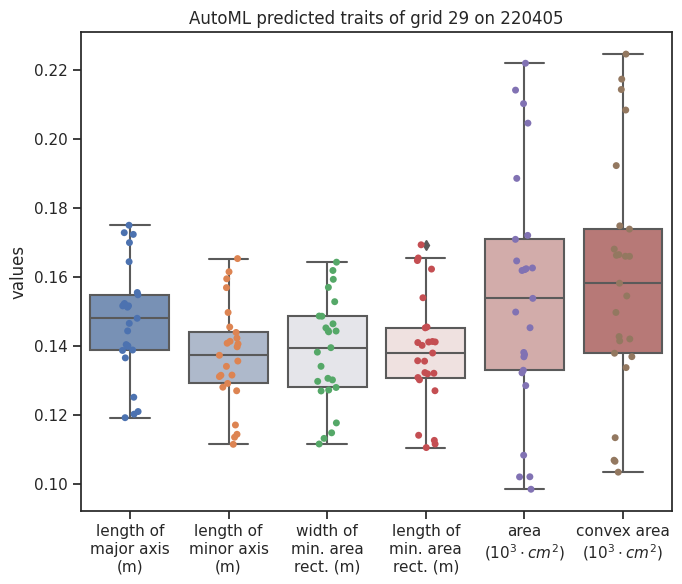

In [27]:
predictions4plot = predictions.copy()
predictions4plot.area /= 1000
predictions4plot.convex_area /= 1000

raw4plot = X.copy()
raw4plot.area /= 1000
raw4plot.convex_area /= 1000

col_rename_dict = {
    'major_axis_length': 'length of\nmajor axis\n(m)', 
    'minor_axis_length': 'length of\nminor axis\n(m)', 
    'min_area_rect_min': 'width of\nmin. area\nrect. (m)',
    'min_area_rect_max': 'length of\nmin. area\nrect. (m)', 
    'area': 'area\n($10^3 \cdot cm^2$)', 
    'convex_area': 'convex area\n($10^3 \cdot cm^2$)',
}

predictions4plot = predictions4plot.rename(columns=col_rename_dict)
raw4plot = raw4plot.rename(columns=col_rename_dict)

f, ax = plt.subplots(figsize=(7, 6))

sns.boxplot(data=predictions4plot, ax=ax, palette="vlag")
sns.stripplot(data=predictions4plot, ax=ax)

# plt.xticks(rotation=-45)

ax.set_title(f'AutoML predicted traits of grid {grid_id} on {date}')
ax.set_ylabel('values')

plt.tight_layout()
# plt.savefig(f'out/autoskl_pred_{date}_{grid_id}.svg')
plt.show()

In [28]:
raw4plot.max().max()

0.21471

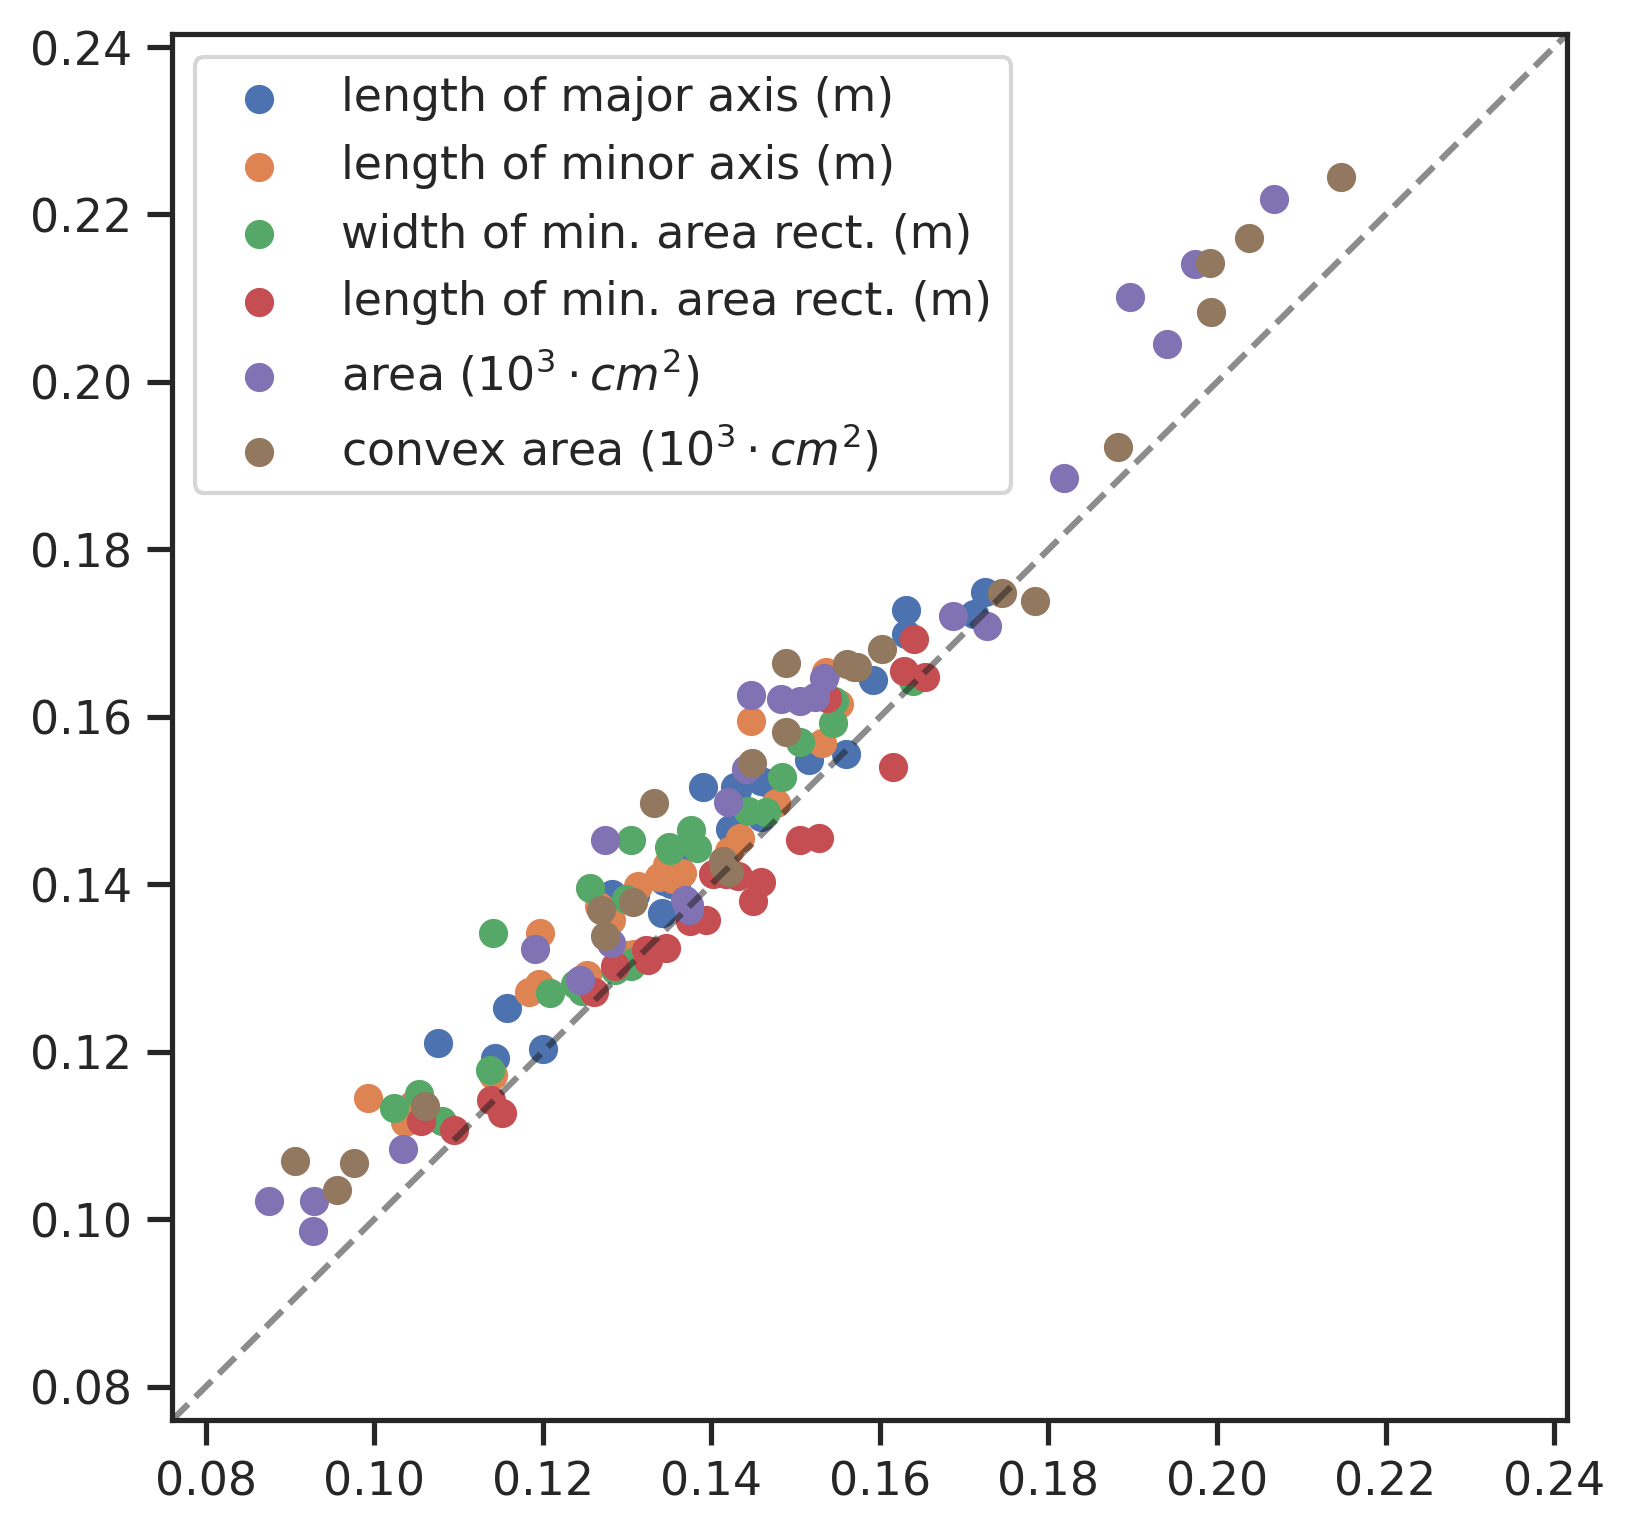

In [29]:
fig, ax = plt.subplots(1,1, figsize=(6,6), dpi=300)

mx = max(raw4plot.max().max(), predictions4plot.max().max())
mn = min(raw4plot.min().min(), predictions4plot.min().min())
mx = np.ceil(100 * mx) / 100 * 1.05
mn = np.floor(100 * mn) / 100 * 0.95

ax.plot([mn, mx], [mn, mx], 'k--', alpha=0.5)

for i in raw4plot.columns:
    ax.scatter(raw4plot[i], predictions4plot[i], label=i.replace('\n', ' '))

ax.set_xlim(mn, mx)
ax.set_ylim(mn, mx)
ax.legend()

plt.show()

# 4. find the closest database

load the database

In [30]:
broccoli_mesh_db = pd.read_excel('out/autoskl_model_db.xlsx')
broccoli_mesh_db

,Date,Field_ID,Model_ID,long_axis(m),short_axis(m),crown_roundness,orientation(degree),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2),head_height(m),crown_height(m),crown_3dconvex_volume(cm3),crown_3dconcave_volume(cm3),head_3dconcave_volume(cm3)
0,20220317,8574,3-1,0.073558,0.062972,0.798339,-65.296804,0.063708,0.061781,31.835893,35.111111,0.142084,0.050574,90.544264,31.423250,42.108040
1,20220317,8575,3-2,0.059003,0.051484,0.930713,-176.139473,0.045497,0.052653,19.398061,23.666667,0.149868,0.040657,50.526204,25.778741,19.931228
2,20220317,8576,3-3,0.052651,0.049139,0.908292,-80.964335,0.048661,0.045269,17.632555,20.111111,0.147616,0.039791,39.632416,14.129421,127.465372
3,20220317,8577,3-4,0.060120,0.053417,0.889342,-78.029467,0.047834,0.053833,20.411755,25.000000,0.146556,0.038978,50.215150,18.277578,50.012442
4,20220317,8578,3-5,0.063628,0.059194,0.920256,-2.246206,0.054661,0.059125,26.335788,29.333333,0.156164,0.047445,73.213668,32.829862,84.052978
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,20220405,5593,8-32,0.154418,0.152340,0.744710,-2.194721,0.145620,0.156182,179.199750,180.222222,0.157322,0.096966,1091.146271,15.990872,49.056136
184,20220405,5594,8-33,0.176361,0.152302,0.797066,-93.464791,0.150877,0.167778,203.381424,208.555556,0.165034,0.125175,1372.151591,34.448384,11.887970
185,20220405,10233,9-31,0.154003,0.142144,0.726698,-62.778655,0.149875,0.138550,167.302718,168.888889,0.178237,0.133220,1356.690145,44.955292,15.085098
186,20220405,10234,9-32,0.152286,0.149501,0.670645,-156.820172,0.151497,0.143503,172.877534,174.777778,0.181256,0.096029,1000.206070,42.004512,9.575636


In [31]:
matching_sort = broccoli_mesh_db[[
     'long_axis(m)', 'short_axis(m)', # 'crown_roundness',
     'min_rect_width(m)', 'min_rect_length(m)', 
     'crown_2dconvex_area(cm2)', 'projected_leaf_area(cm2)']]
matching_sort

,long_axis(m),short_axis(m),min_rect_width(m),min_rect_length(m),crown_2dconvex_area(cm2),projected_leaf_area(cm2)
0,0.073558,0.062972,0.063708,0.061781,31.835893,35.111111
1,0.059003,0.051484,0.045497,0.052653,19.398061,23.666667
2,0.052651,0.049139,0.048661,0.045269,17.632555,20.111111
3,0.060120,0.053417,0.047834,0.053833,20.411755,25.000000
4,0.063628,0.059194,0.054661,0.059125,26.335788,29.333333
...,...,...,...,...,...,...
183,0.154418,0.152340,0.145620,0.156182,179.199750,180.222222
184,0.176361,0.152302,0.150877,0.167778,203.381424,208.555556
185,0.154003,0.142144,0.149875,0.138550,167.302718,168.888889
186,0.152286,0.149501,0.151497,0.143503,172.877534,174.777778


/tmp/ipykernel_7428/4099263589.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color = plt.cm.get_cmap('plasma', len(predictions))


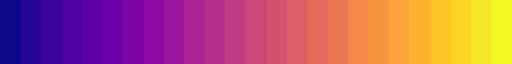

In [32]:
color = plt.cm.get_cmap('plasma', len(predictions))
color

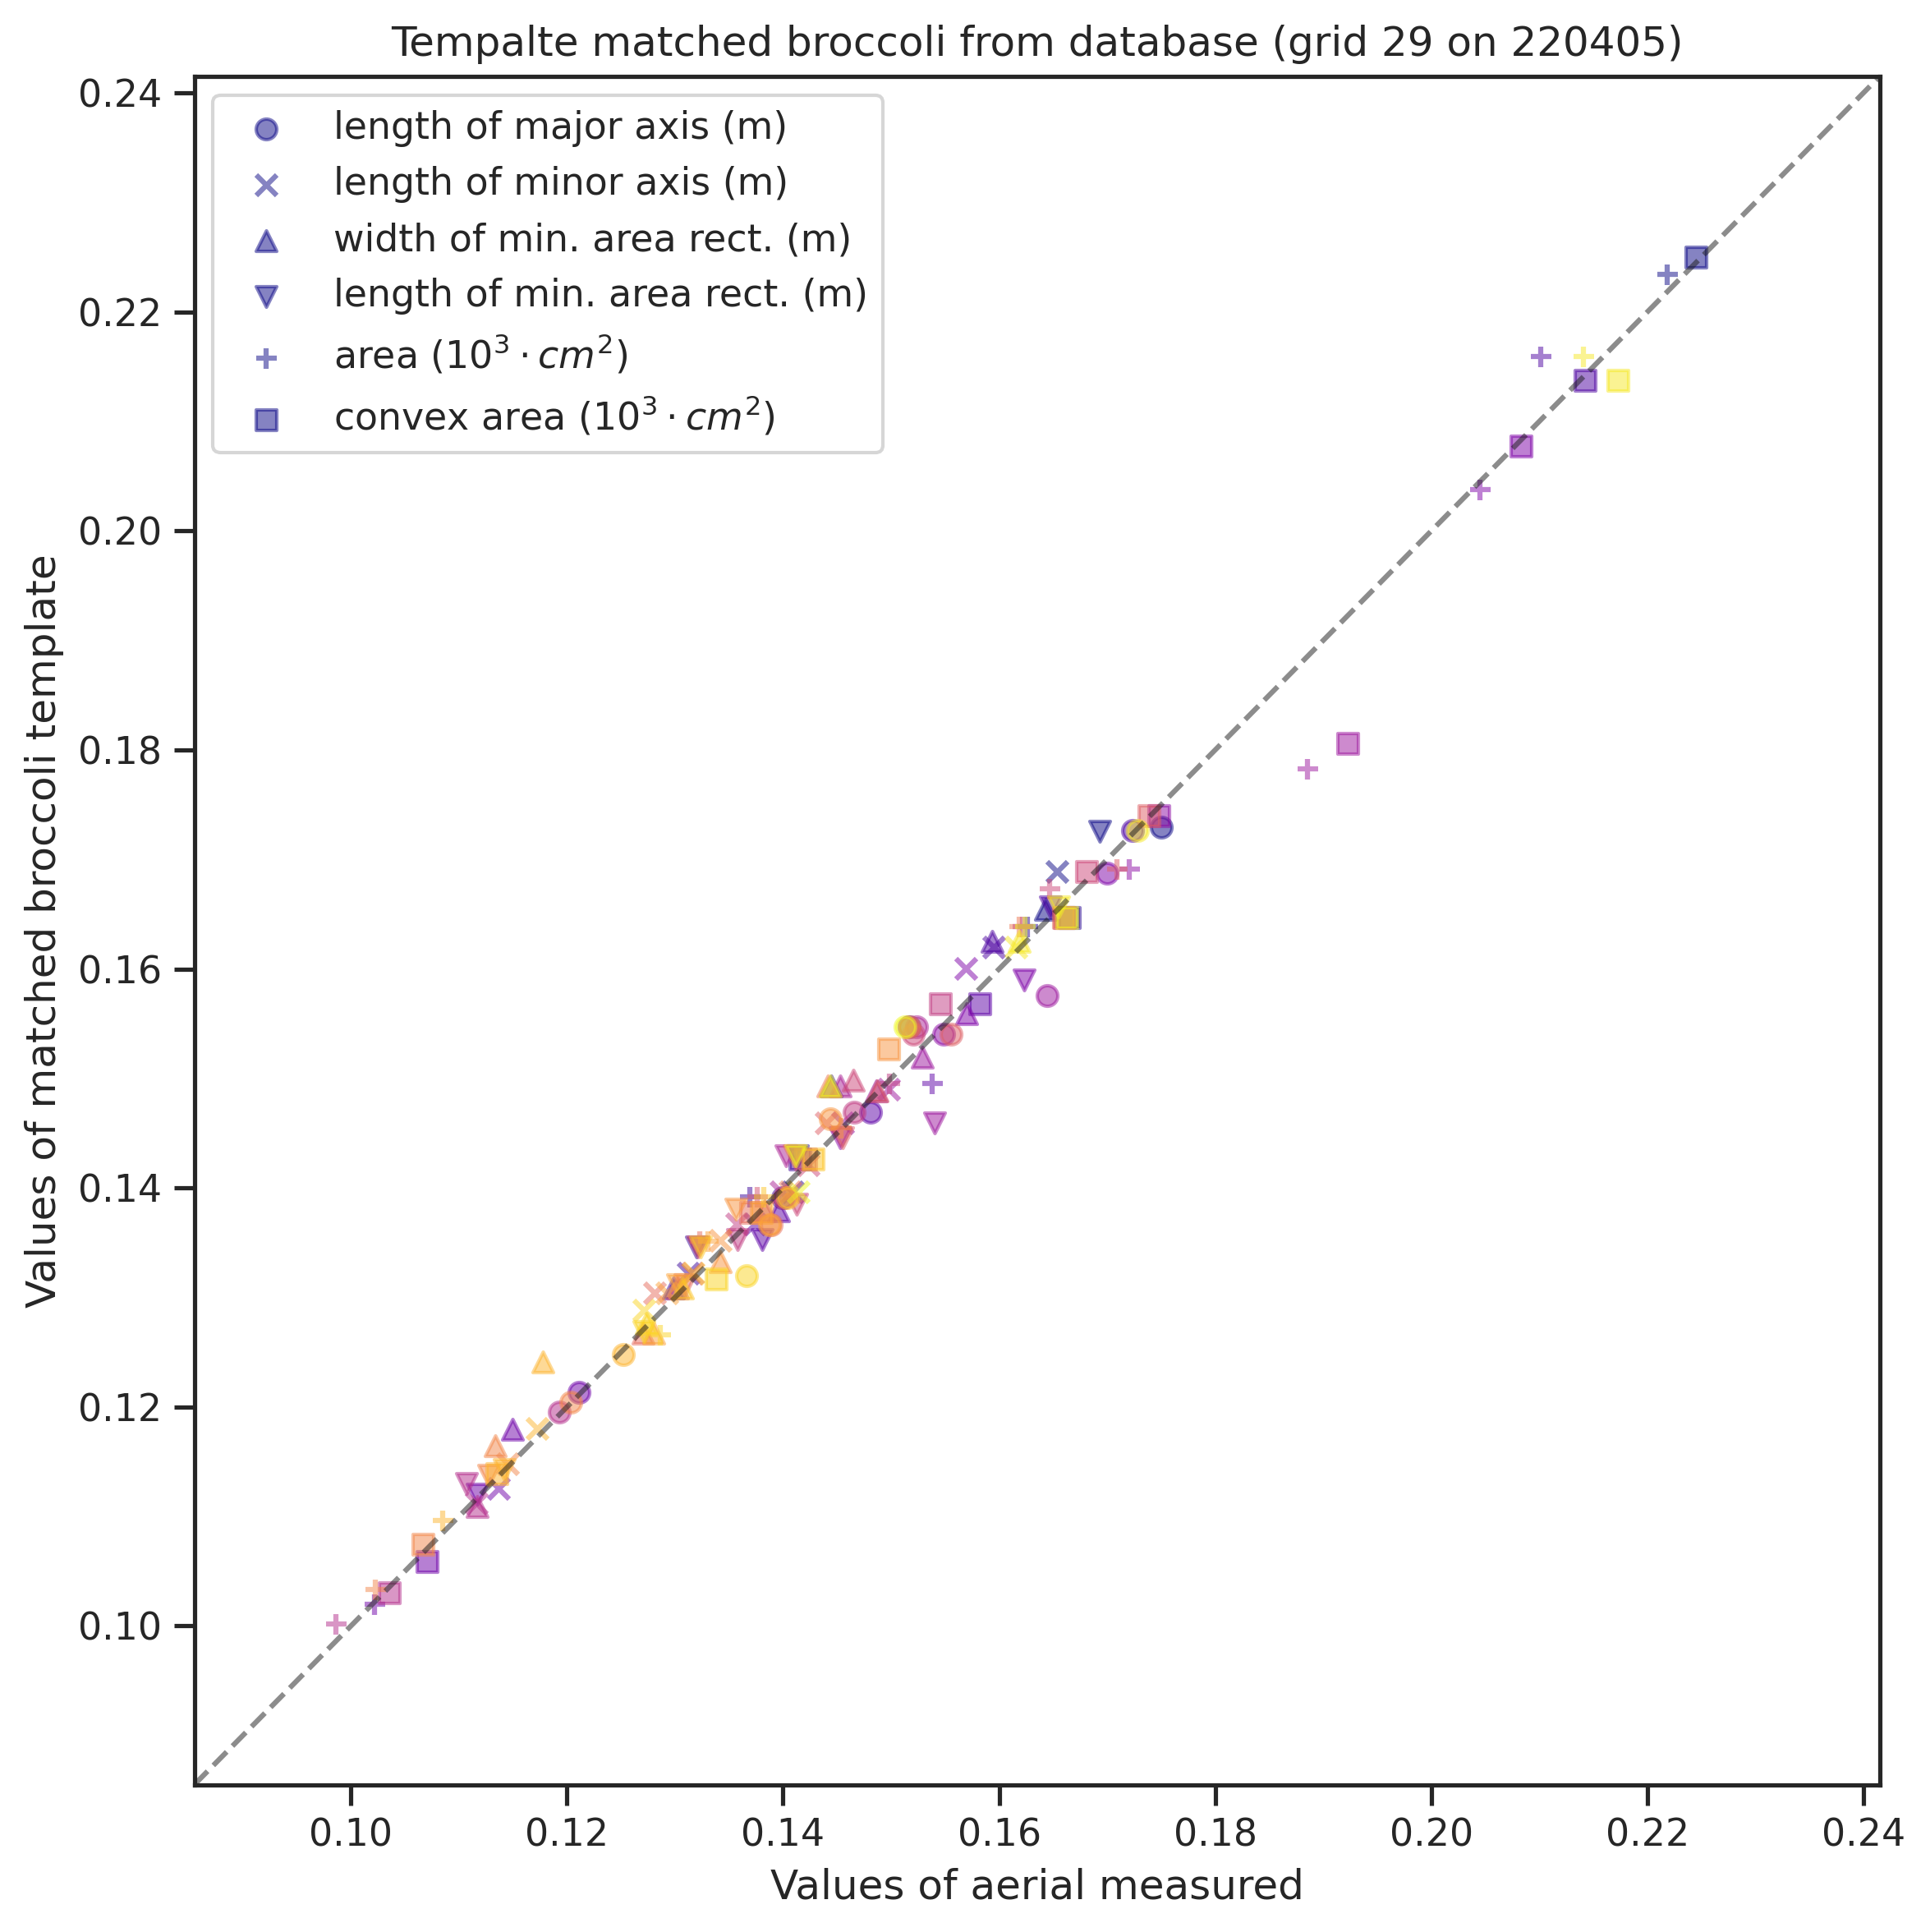

In [33]:
fig, ax = plt.subplots(1,1, figsize=(8,8), dpi=300)

mx = predictions4plot.max().max()
mn = predictions4plot.min().min()
mx = np.ceil(100 * mx) / 100 * 1.05
mn = np.floor(100 * mn) / 100 * 0.95

trans = []
matched_idx = []

# lbmax = np.ceil( 0.01 * matching_sort.values.max()) / 10

lbmax = mx
lbmin = mn

# ax.plot([0, lbmax], [0, lbmax], 'k--', alpha=0.5)
ax.plot([lbmin, lbmax], [lbmin, lbmax], 'k--', alpha=0.5)

marker=['o', 'x', '^', 'v', '+', 's']
labels = [
    'length of major axis (m)',
    'length of minor axis (m)',
    'width of min. area rect. (m)',
    'length of min. area rect. (m)', 
    'area ($10^3 \cdot cm^2$)',
    'convex area ($10^3 \cdot cm^2$)'
]

for row_id, v in predictions.iterrows():
    diff = matching_sort.values - v.values
    # normalize
    diff_norm = np.abs(diff / np.linalg.norm(diff, axis=0))
    diff_sum = diff_norm.sum(axis=1)

    min_diff_idx = np.argmin(diff_sum)

    pred_v = v.values
    db_v = matching_sort.values[min_diff_idx,:]

    plot_ratio = np.array([1, 1, 1, 1, 0.001, 0.001])
    xx = pred_v*plot_ratio
    yy = db_v*plot_ratio
    for i in range(len(xx)):
        if row_id == 0:
            ax.scatter(x=xx[i], y=yy[i], alpha=0.5, marker=marker[i], color=color(row_id), label=labels[i])
        else:
            ax.scatter(x=xx[i], y=yy[i], alpha=0.5, marker=marker[i], color=color(row_id))

    # [2]'min_rect_width(m)', [3] 'min_rect_length(m)', 
    trans.append((pred_v[2]/db_v[2], pred_v[3]/db_v[3]))
    matched_idx.append(min_diff_idx)
    
ax.set_xlim(lbmin, lbmax)
ax.set_ylim(lbmin, lbmax)

# ax.text(lbmin*1.01, lbmax*0.99, 
#     'Traits Units \n\n'
#     'length of major axis (m)\n' + 
#     'length of minor axis (m)\n' + 
#     'width of min. area rect. (m)\n' + 
#     'length of min. area rect. (m)\n'+ 
#     'area ($1000cm^2$)\n' + 
#     'convex area ($1000cm^2$)\n',
#     va='top')
ax.set_xlabel('Values of aerial measured')
ax.set_ylabel('Values of matched broccoli template')
ax.set_title(f'Tempalte matched broccoli from database (grid {grid_id} on {date})')
ax.legend()
plt.tight_layout()
# plt.savefig(f"out/autoskl_matched_{date}_{grid_id}.svg")
# plt.savefig(f"out/aerial_matched_{date}_{grid_id}.pdf")
plt.show()

In [44]:
from regression import linear

214.71 87.57
y=1.012x+-2.284  R^2=0.88
RMSE = 2.7620672738039773
-----------------
224.47699785232544 98.61977124214172
y=0.931x+11.831  R^2=0.94
RMSE = 2.34115828867202
-----------------


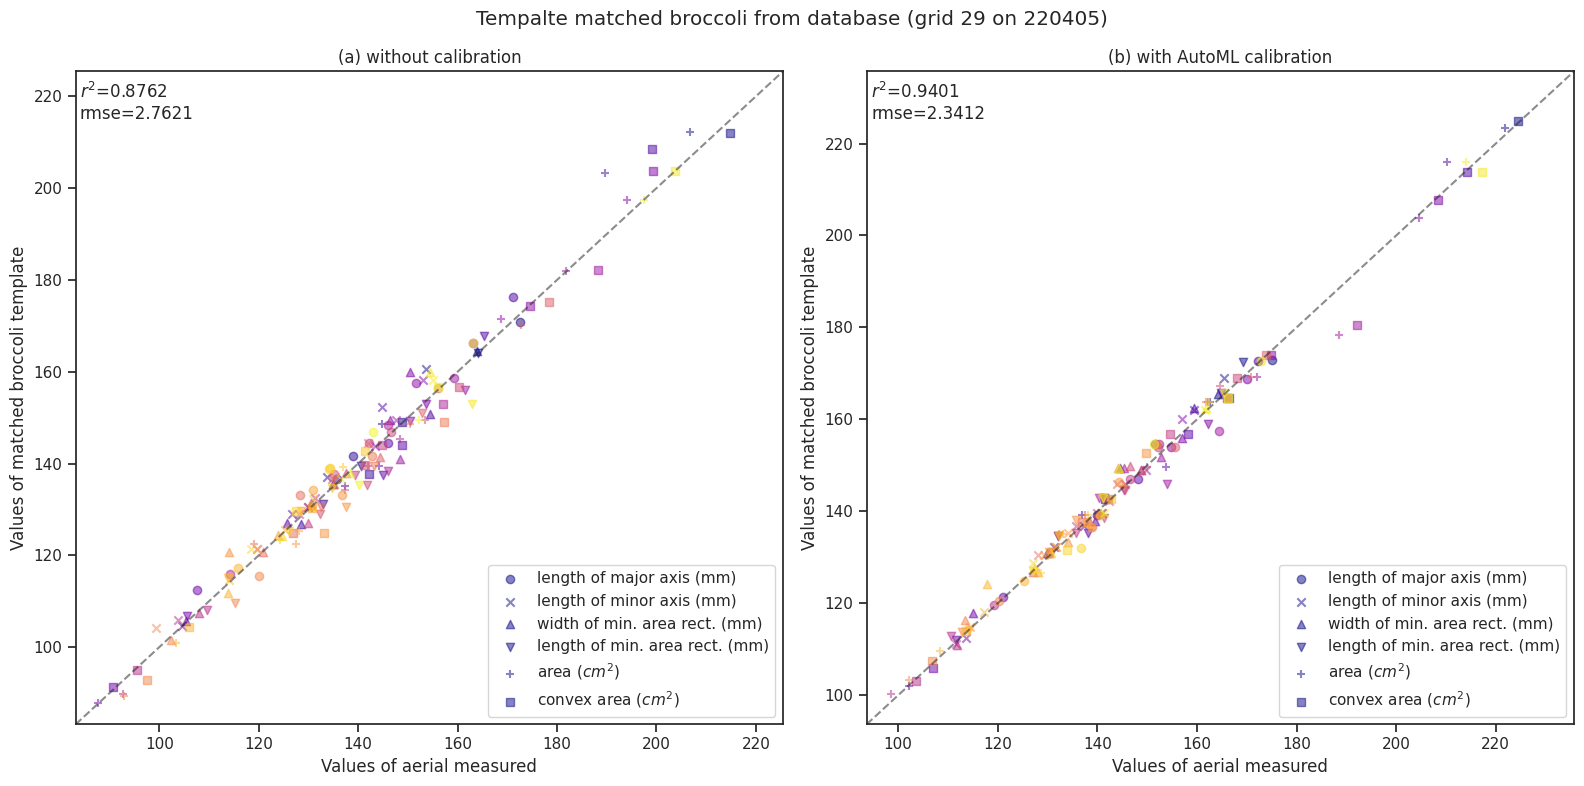

In [57]:
fig, axes = plt.subplots(1,2, figsize=(16,8))

trans = []
matched_idx = []


# plot_ratio = np.array([1, 1, 1, 1, 0.001, 0.001])
plot_ratio = np.array([1000, 1000, 1000, 1000, 1, 1])

# lbmax = np.ceil( 0.01 * matching_sort.values.max()) / 10

iters = [X.copy(), predictions]

subtitles = ['(a) without calibration', '(b) with AutoML calibration']

for i in range(2):
    ax = axes[i]

    mx = (iters[i].values*plot_ratio).max().max()
    mn = (iters[i].values*plot_ratio).min().min()
    print(mx, mn)
    lbmax = np.ceil(100 * mx) / 100 * 1.05
    lbmin = np.floor(100 * mn) / 100 * 0.95

    # ax.plot([0, lbmax], [0, lbmax], 'k--', alpha=0.5)
    ax.plot([lbmin, lbmax], [lbmin, lbmax], 'k--', alpha=0.5)

    marker=['o', 'x', '^', 'v', '+', 's']
    labels = [
        'length of major axis (mm)',
        'length of minor axis (mm)',
        'width of min. area rect. (mm)',
        'length of min. area rect. (mm)', 
        'area ($cm^2$)',
        'convex area ($cm^2$)'
    ]

    for row_id, v in iters[i].iterrows():
        diff = matching_sort.values - v.values
        # normalize
        diff_norm = np.abs(diff / np.linalg.norm(diff, axis=0))
        diff_sum = diff_norm.sum(axis=1)

        min_diff_idx = np.argmin(diff_sum)

        pred_v = v.values
        db_v = matching_sort.values[min_diff_idx,:]

        xx = pred_v*plot_ratio
        yy = db_v*plot_ratio
        for j in range(len(xx)):
            if row_id == 0:
                ax.scatter(x=xx[j], y=yy[j], alpha=0.5, marker=marker[j], color=color(row_id), label=labels[j])
            else:
                ax.scatter(x=xx[j], y=yy[j], alpha=0.5, marker=marker[j], color=color(row_id))

        # [2]'min_rect_width(m)', [3] 'min_rect_length(m)', 
        trans.append((pred_v[2]/db_v[2], pred_v[3]/db_v[3]))
        matched_idx.append(min_diff_idx)
        
    ax.set_xlim(lbmin, lbmax)
    ax.set_ylim(lbmin, lbmax)

    x_points, y_points, y_predict, t, r2, rmse_v = linear(xx.flatten(), yy.flatten())

    ax.text(lbmin*1.01, lbmax*0.99, 
        # 'Traits Units \n\n'
        # 'length of major axis (m)\n' + 
        # 'length of minor axis (m)\n' + 
        # 'width of min. area rect. (m)\n' + 
        # 'length of min. area rect. (m)\n'+ 
        # 'area ($1000cm^2$)\n' + 
        # 'convex area ($1000cm^2$)\n',
        f'$r^2$={round(r2, 4)}\nrmse={round(rmse_v, 4)}',
        va='top', ha='left')
    ax.set_xlabel('Values of aerial measured')
    ax.set_ylabel('Values of matched broccoli template')
    ax.set_title(subtitles[i])
    ax.legend(loc='lower right')

plt.suptitle(f'Tempalte matched broccoli from database (grid {grid_id} on {date})')
plt.tight_layout()
# plt.savefig(f"out/autoskl_matched_{date}_{grid_id}.svg")
plt.savefig(f"out/aerial_matched_compare_{date}_{grid_id}.pdf")
plt.show()

In [22]:
trans

[(1.013371925110295, 0.9660548408178999),
 (1.006545837993817, 0.9813256325277521),
 (0.9854684934898619, 0.9777045969114111),
 (0.9861528316107696, 0.9952041256913868),
 (1.0289341328071409, 0.9922877163952144),
 (1.005836354763333, 0.9832407367826034),
 (0.9681928860456174, 0.9838086356696073),
 (1.0024996782571587, 1.0107576073785702),
 (1.0004199460488024, 0.9907569901017947),
 (1.036626012910844, 0.9825467818273428),
 (1.004775070674483, 0.982677373694478),
 (0.9627507564346994, 1.0134440027506326),
 (0.9953178573215333, 0.9957277780346476),
 (1.0083371534883045, 0.9793992989640933),
 (0.9964159583063469, 1.0054122234436302),
 (1.0282918456366497, 1.0050505758752144),
 (1.0124513472910595, 0.9989211607669243),
 (0.9644463237205793, 1.0064913861384406),
 (1.026455033943335, 0.9934580427945623)]

combine scales + positions (translate)

In [23]:
for i, row in broccoli_2d_in_grid_poly.iterrows():
    print(row)

    break

index                                                              36142
date                                                          20220405_0
label                                                                946
area                                                                1745
convex_area                                                         1819
eccentricity                                                    0.726792
equivalent_diameter                                            47.136005
major_axis_length                                               57.17419
minor_axis_length                                              39.270538
min_area_rect_max                                                   55.0
min_area_rect_min                                                   41.0
perimeter                                                      166.01829
circularity                                                     0.795598
circular_x                                         

In [24]:
polygon_np = np.array(eval(row.polygon))

In [25]:
polygon_xyz = grid_pcd.crop_point_cloud(polygon_np)
polygon_xyz

              x            y        z  r       g       b           nx      ny      nz
  0  368073.892  3956011.486   96.783  nodata  nodata  nodata  nodata  nodata  nodata
  1  368073.906  3956011.481   96.799  nodata  nodata  nodata  nodata  nodata  nodata
  2  368073.9    3956011.475   96.791  nodata  nodata  nodata  nodata  nodata  nodata
...     ...          ...      ...      ...     ...     ...        ...     ...     ...
 88  368073.912  3956011.45    96.808  nodata  nodata  nodata  nodata  nodata  nodata
 89  368073.914  3956011.476   96.813  nodata  nodata  nodata  nodata  nodata  nodata
 90  368073.914  3956011.496   96.808  nodata  nodata  nodata  nodata  nodata  nodata

(array([ 5., 11., 11.,  9.,  8., 10., 11., 11.,  7.,  8.]),
 array([96.7664 , 96.77245, 96.7785 , 96.78455, 96.7906 , 96.79665,
        96.8027 , 96.80875, 96.8148 , 96.82085, 96.8269 ]),
 <BarContainer object of 10 artists>)

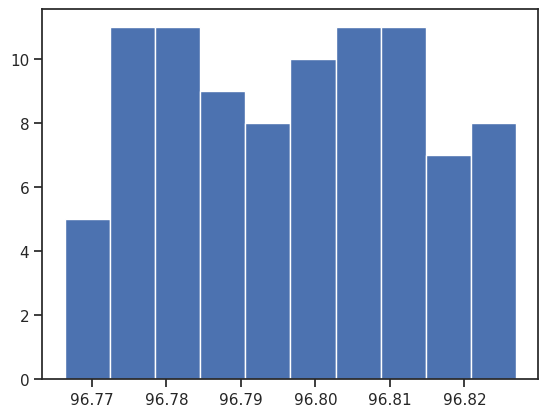

In [26]:
plt.hist(polygon_xyz.points[:,2])

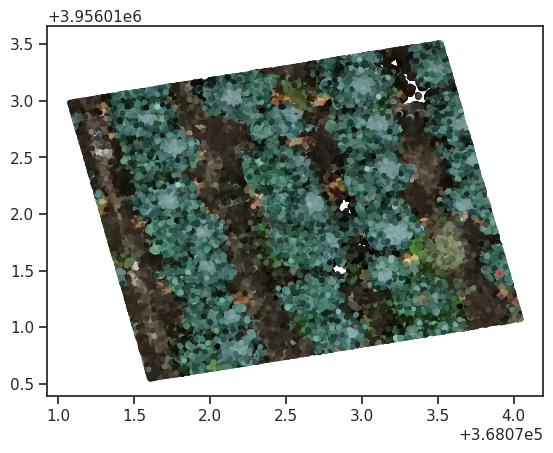

In [27]:
plt.scatter(grid_pcd.points[:,0], grid_pcd.points[:,1], color=grid_pcd.colors/255, marker='.')
plt.plot(*polygon_np.T, color='r')

In [28]:
for i, row in broccoli_2d_in_grid_poly.iterrows():
    polygon_np = np.array(eval(row.polygon))
    polygon_xyz = grid_pcd.crop_point_cloud(polygon_np)
    ht_values = polygon_xyz.points[:,2]

    # 95% percentile ht
    thresh = np.percentile(ht_values, 95, axis=0)
    z_pos = np.mean(ht_values[ht_values >= thresh])

    # offseted
    x_pos = row.circular_x - grid_pcd.offset[0]
    y_pos = row.circular_y - grid_pcd.offset[1]
    z_pos -= grid_pcd.offset[2]

    print(x_pos, y_pos, z_pos)

    break

1.3432109051500447 -0.5550566129386425 0.14735999999999194


In [29]:
grid_pcd.offset

array([ 368072.56355, 3956012.0283 ,      96.6785 ])

In [30]:
def to_open3d(idp_pcd):
    final_pcd = o3d.geometry.PointCloud()
    final_pcd.points = o3d.utility.Vector3dVector(idp_pcd._points)
    color_np = idp_pcd.colors/255
    # color_np = np.insert(color_np, 2, 0.5, axis=1)
    # print(color_np)
    final_pcd.colors = o3d.utility.Vector3dVector(color_np)

    return final_pcd

In [31]:
grid_pcd_o3d = to_open3d(grid_pcd)

In [58]:
o3d.visualization.draw_geometries([grid_pcd_o3d])

find the mesh models

In [32]:
mesh_database_path = r"out/v230407/ztopmash"

mesh_db = {}
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db[file[:-4]] = os.path.join(mesh_database_path, file)

In [33]:
matched_slice = broccoli_mesh_db.iloc[matched_idx[i]]
matched_slice

Date                             20220324
Field_ID                             6344
Model_ID                              2-7
long_axis(m)                     0.085206
short_axis(m)                    0.082518
crown_roundness                  0.858963
orientation(degree)           -119.178693
min_rect_width(m)                0.077943
min_rect_length(m)               0.080119
crown_2dconvex_area(cm2)        49.160402
projected_leaf_area(cm2)        54.888889
head_height(m)                    0.14794
crown_height(m)                  0.061178
crown_3dconvex_volume(cm3)     186.862746
crown_3dconcave_volume(cm3)      4.895552
head_3dconcave_volume(cm3)      16.978565
Name: 36, dtype: object

In [56]:
line_set = o3d.geometry.LineSet()

line_set.points = o3d.utility.Vector3dVector(np.array([[0,0,0],[0.1,0,0],[0,0.1,0], [0,0,0.1]]))
line_set.lines = o3d.utility.Vector2iVector([[0,1],[0,2],[0,3]])
line_set.colors = o3d.utility.Vector3dVector(np.array([[1,0,0],[0,1,0],[0,0,1]]))

In [34]:
mesh_db[matched_slice.Model_ID]

'out/v230407/ztopmash/2-7.obj'

In [35]:
mesh = o3d.io.read_triangle_mesh(mesh_db[matched_slice.Model_ID],  enable_post_processing=True)

In [34]:
o3d.visualization.draw_geometries([line_set, mesh])

In [42]:
r = Rotation.from_euler('z', matched_slice['orientation(degree)'], degrees=True)
r.as_matrix()

array([[-0.01235599,  0.99992366,  0.        ],
       [-0.99992366, -0.01235599, -0.        ],
       [-0.        ,  0.        ,  1.        ]])

In [68]:
r.inv().as_matrix()

array([[-0.01235599, -0.99992366, -0.        ],
       [ 0.99992366, -0.01235599,  0.        ],
       [ 0.        , -0.        ,  1.        ]])

In [78]:
m_trans = copy(mesh).rotate(r.as_matrix())

# scale
m_trans.vertices = o3d.utility.Vector3dVector(
    np.asarray(m_trans.vertices) * np.array([trans[i][0], trans[i][1], 1]) 
)
# by testing, the x -> width, y -> length
# trans -> # [0]'min_rect_width(m)', [1] 'min_rect_length(m)', 
m_trans_back = copy(m_trans).rotate(r.inv().as_matrix())

In [79]:
o3d.visualization.draw_geometries([line_set, mesh, m_trans.translate((0, 0.2, 0)),  m_trans_back.translate((0.2, 0, 0))])

In [39]:
# phi = matched_slice['orientation(degree)']
# trans -> # [0]'min_rect_width(m)', [1] 'min_rect_length(m)', 
# maj_x = np.cos(np.deg2rad(phi)) * trans[i][1] # major_axis
# maj_y = np.sin(np.deg2rad(phi)) * trans[i][1] # major_axis
# min_x = np.sin(np.deg2rad(phi)) * trans[i][0] # plant.minor_axis
# min_y = np.cos(np.deg2rad(phi)) * trans[i][0] # plant.minor_axis

# print(phi, maj_x, maj_y, min_x, min_y)

-90.70796401410178 -0.012273309612556633 -0.9932327616381695 -1.0036990204839855 -0.012402640460532282


In [87]:
o3d.visualization.draw_geometries([
    grid_pcd_o3d, 
    mesh.translate((x_pos, y_pos, z_pos))])

In [36]:
broccoli_mesh_container = []
for i, row in broccoli_2d_in_grid_poly.iterrows():
    polygon_np = np.array(eval(row.polygon))
    polygon_xyz = grid_pcd.crop_point_cloud(polygon_np)
    ht_values = polygon_xyz.points[:,2]

    # 95% percentile ht
    thresh = np.percentile(ht_values, 95, axis=0)
    z_pos = np.mean(ht_values[ht_values >= thresh])

    # offseted
    x_pos = row.circular_x - grid_pcd.offset[0]
    y_pos = row.circular_y - grid_pcd.offset[1]
    z_pos -= grid_pcd.offset[2]

    # find
    matched_slice = broccoli_mesh_db.iloc[matched_idx[i]]
    mesh = o3d.io.read_triangle_mesh(mesh_db[matched_slice.Model_ID],  enable_post_processing=True)

    r = Rotation.from_euler('z', matched_slice['orientation(degree)'], degrees=True)
    m_trans = copy(mesh).rotate(r.as_matrix())

    # scale
    m_trans.vertices = o3d.utility.Vector3dVector(
        np.asarray(m_trans.vertices) * np.array([trans[i][0], trans[i][1], 1]) 
    )
    # by testing, the x -> width, y -> length
    # trans -> # [0]'min_rect_width(m)', [1] 'min_rect_length(m)', 
    m_trans_back = copy(m_trans).rotate(r.inv().as_matrix())

    broccoli_mesh_container.append(m_trans_back.translate((x_pos, y_pos, z_pos)))

In [37]:
o3d.visualization.draw_geometries([grid_pcd_o3d] + broccoli_mesh_container)

# 5. preview by open3d